# Chapter 3: Answers from the future: known that morning?
*Leakage and the prediction-time question · also searched as: data leakage in machine
learning, target leakage, train test contamination*

Kalpa's junior joined `settlement_status` from the payments feed and validation jumped to
0.99. The data platform lead, reading the schema, said the field is written after delivery,
when the payment clears. This chapter shows on twelve invented members why that column
scores perfectly in training and cannot score at all on the morning the nudge goes out.

**Who needs the answer.** Kalpa's marketing lead, who wants the 0.99 shipped tonight, and the
data platform lead, who knows when each field is written.

**The questions on the way.** Why does one column score twelve out of twelve? What does the
same column hold on the nudge morning? What is the one question that catches it? What does
the honest score look like?

**You will be able to** place every column on a timeline against the prediction moment, ask
the prediction-time question, and explain why the score fell and the model got better.

## Why does one column score twelve out of twelve?
Twelve invented members as the training table holds them, ninety days after the nudge, when
the outcome is known. A rule on one column predicts "bought" when the column says so.

**Predict before you run.** The rule "bought if settlement_status is settled" gets (A) about
half right; (B) 10 of 12; (C) 12 of 12.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

k = pd.DataFrame({                     # invented teaching table, twelve Kalpa members
    "member": [f"M{i:02d}" for i in range(1, 13)],
    "days_since_last_order": [3, 40, 6, 12, 75, 2, 30, 9, 55, 4, 20, 90],
    "orders_90d":            [6, 1, 4, 3, 0, 7, 2, 4, 1, 5, 2, 0],
    "settlement_status": ["settled", "none", "settled", "none", "none", "settled",
                          "settled", "none", "none", "settled", "settled", "none"],
    "bought_90d":            [1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0],
})
def right(rule):
    return int((rule.astype(int) == k["bought_90d"]).sum())
print("settled -> bought:", right(k["settlement_status"] == "settled"), "of 12")
print("orders_90d >= 2 -> bought:", right(k["orders_90d"] >= 2), "of 12")
print("days_since_last_order <= 6 -> bought:", right(k["days_since_last_order"] <= 6), "of 12")
k

settled -> bought: 12 of 12
orders_90d >= 2 -> bought: 10 of 12
days_since_last_order <= 6 -> bought: 10 of 12


,member,days_since_last_order,orders_90d,settlement_status,bought_90d
0,M01,3,6,settled,1
1,M02,40,1,none,0
2,M03,6,4,settled,1
3,M04,12,3,none,0
4,M05,75,0,none,0
5,M06,2,7,settled,1
6,M07,30,2,settled,1
7,M08,9,4,none,0
8,M09,55,1,none,0
9,M10,4,5,settled,1


**What happened.** C. The settlement rule is perfect, and the best honest rule, two or more
orders in 90 days, gets 10 of 12. A payment can only settle for a member who bought, so the
column is the answer written in the payments team's words.

## What does the same column hold on the nudge morning?
The model runs on the nudge morning, before anyone has bought. On that morning no payment
from the coming 90 days exists, so `settlement_status` reads `none` for every member.

**Predict before you run.** On the nudge morning the settlement rule gets (A) 12 of 12;
(B) 6 of 12, the score of predicting that nobody buys.

In [2]:
morning = k.assign(settlement_status="none")       # what the scoring service sees that morning
print("settlement rule on the nudge morning:", right(morning["settlement_status"] == "settled"), "of 12")
print("predict nobody buys:", int((k["bought_90d"] == 0).sum()), "of 12")

settlement rule on the nudge morning: 6 of 12
predict nobody buys: 6 of 12


**What happened.** B. The perfect rule collapses to "nobody buys", 6 of 12. The 0.99 was
measured on a table built after the outcome, and the model would meet a table built before
it. That gap is leakage: an input the model sees in training that would not be known at the
moment it is used.

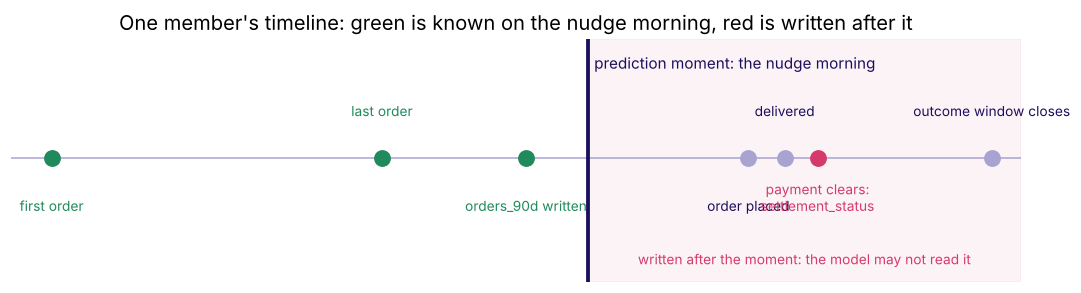

In [3]:
events = [("first order", -400, GREEN), ("last order", -9, GREEN), ("orders_90d written", -1, GREEN),
          ("nudge morning", 0, INK), ("order placed", 5, GREY), ("delivered", 8, GREY),
          ("payment clears:\nsettlement_status", 12, ROSE), ("outcome window closes", 90, GREY)]
pos = lambda t: np.sign(t) * np.log10(abs(t) + 1)
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.axhline(0, color=GREY, lw=1)
ax.axvline(0, color=INK, lw=2.5)
ax.axvspan(0, 2.1, color=ROSE, alpha=0.06)
for i, (name, t, c) in enumerate(events):
    if t == 0:
        continue
    y = 0.35 if i % 2 else -0.45
    ax.plot(pos(t), 0, "o", color=c, ms=10)
    ax.text(pos(t), y, name, ha="center", fontsize=9, color=c if c != GREY else INK)
ax.text(0.03, 0.75, "prediction moment: the nudge morning", color=INK, fontsize=10)
ax.text(1.05, -0.9, "written after the moment: the model may not read it", color=ROSE, ha="center", fontsize=9)
ax.set_xlim(-2.8, 2.1); ax.set_ylim(-1.05, 1.0); ax.set_yticks([]); ax.set_xticks([])
ax.spines[:].set_visible(False)
ax.set_title("One member's timeline: green is known on the nudge morning, red is written after it")
plt.tight_layout(); plt.show()

## What is the one question that catches it?
**The prediction-time question: on the morning the model is used, do we know this value
for this customer?** It is asked of every column, with the system that writes it and the
moment it is written. `orders_90d` is written nightly before the nudge: known. The
settlement status is written days after the order: not known, so it is dropped, however
well it scores. Two more routes carry the future in: a scaler or encoder fitted on all rows
before the split, and rows from after the prediction moment sitting in the training set.

In [4]:
honest = right(k["orders_90d"] >= 2)
check("the settlement rule is perfect on the training table", right(k["settlement_status"] == "settled") == 12)
check("on the nudge morning it falls to the do-nothing score", right(morning["settlement_status"] == "settled") == int((k["bought_90d"] == 0).sum()))
check("the best honest rule scores between the two", 6 < honest < 12)

PASS  the settlement rule is perfect on the training table
PASS  on the nudge morning it falls to the do-nothing score
PASS  the best honest rule scores between the two


## What are the rules, and what flips each one?
1. A column is allowed only if it is known at the prediction moment; a column written later
   is dropped, whatever it scores.
2. A score that jumps on one new column is a suspect until its write time is checked; a
   jump with a known business cause, such as a new and legitimate data source, survives.
3. "Too good" is a reason to ask the question and never the verdict: a strong column that
   was known in time stays.
4. The honest score is the one to ship, and it is lower: the score fell and the model got
   better, because the leaked model cannot run on the morning it is needed.

Chapter 4 turns the question into an audit of every column, with a verdict and a reason.